# Notebook - Analisis exploratorio de datos chubut

**Objetivo**: Explorar los eventos de protestas relacionados con la provincia de chubut

**Fuente**: Base de datos con eventos de protetas de Chubut y Jujuy 

**Autor**: Federico Nicolas LLanes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel('../data/processed/eventos_chubut_jujuy.xlsx')

In [3]:
df

,Unnamed: 0,noticia_id,provincia,localidad,actores_participantes,demanda_principal,tipo_accion,tipo_accion_detalle,disrupcion,escala,...,demanda_derechos_especificos,demanda_institucional,demanda_conmemoracion,tiene_marcha,tiene_corte,tiene_paro,tiene_acto,tiene_escrache,tiene_destrozos,tiene_toma
0,0,2021103100,Chubut,Chubut,Sindicato de la Salud Pública,Pago de deuda de paritarias y retroactivos,Paro,trabajo a reglamento,1.0,media,...,0,0,0,0,0,1,0,0,0,0
1,1,2021110100,Chubut,No especificado,No especificado,No especificado,No especificado,No especificado,99.0,No especificado,...,0,0,0,0,0,0,0,0,0,0
2,2,2021110200,Chubut,Rawson,Auxiliares de la educación,falta de convocatoria a paritarias salariales,Corte,Ruta provincial Nº 7,1.0,media,...,0,0,0,0,1,0,0,0,0,0
3,3,2021110202,Chubut,Esquel,Miembros de comunidades originarias,solución a la titularidad de tierras,Toma de edificio,ocupación del edificio del IAC,1.0,baja,...,0,0,0,0,0,0,0,0,0,1
4,4,2021110202,Chubut,Esquel,Miembros de comunidades originarias,No especificado,Toma de edificio,ocupación en la Secretaría de Bosques,1.0,baja,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,182,2023080101,Jujuy,CABA (fuera de Jujuy),Tercer Malón de la Paz,Contra Reforma / Por la Ley de Propiedad Comun...,Marcha,;ovilización / actividad de visibilización,0.0,Media,...,0,0,0,1,0,0,0,0,0,0
183,183,2023080102,Jujuy,San Salvador de Jujuy,Docentes(secundarios y terciarios),Salarial,Mixta,movilización mixta,1.0,Baja,...,0,0,0,0,0,0,0,0,0,0
184,184,2023080301,Jujuy,San Salvador de Jujuy,Docentes/ Gremios docentes,Salarial/ Derecho a protesta,Mixta,movilización / paro,1.0,Media,...,0,0,0,0,0,1,0,0,0,0
185,185,2023080501,Jujuy,San Salvador de Jujuy,La multisectorial,Contra Reforma/Salarial/ Apoyo Malón de la Paz,Marcha,marcha de antorchas,0.0,Alta,...,0,0,1,1,0,0,0,0,0,0


In [4]:
df_ch = df[df["provincia"] == "Chubut"]

In [5]:
df.dtypes

Unnamed: 0                         int64
noticia_id                         int64
provincia                            str
localidad                            str
actores_participantes                str
demanda_principal                    str
tipo_accion                          str
tipo_accion_detalle                  str
disrupcion                       float64
escala                            object
intensidad                        object
respuesta_estatal                    str
presencia_policial               float64
accionar_policial                  int64
tipo_intervencion_estatal        float64
uso_fuerza                       float64
heridos                          float64
detenciones                      float64
judicializacion                  float64
coord_interinstitucional         float64
canales_informales               float64
amenaza_politica                 float64
resultado_episodio               float64
fuente                               str
observaciones   

## Panorama general


Se realiza un ánalisis básico de la base: cantidad de eventos, distribución por localidad y cobertura temporal. El objetivo es verificar que el recorte (Chubut Octubre 2021 - Enero 2022) este bien representado y detectar concentraciones geográficas o temporales

In [6]:
print(f"Chubut: {len(df_ch)} eventos")

Chubut: 121 eventos


#### Concentración por localidad

In [7]:
print(df_ch["localidad"].value_counts().head(10))

localidad
Rawson                26
Trelew                25
Chubut                16
Esquel                16
No especificado       10
Puerto Madryn          8
Madryn                 5
El Bolsón              3
Comodoro Rivadavia     2
Puerto Rawson          1
Name: count, dtype: int64


La concetración de eventos está en Rawson con 26 eventos y Trelew con 25, seguidas por Esquel y Puerto Madryn. Hay 16 eventos registrados como Chubut sin locacidad especifica probablemente corresponden a noticias que no precisan la ciudad. Hay 3 casos localizados en el Bolson, esto es un hallazgo interesante ya que se trata de una localidad de Rio Negro, podria tratarse de noticias que ocurren en la zona limitrofe entre ambas provincias.

#### Distribución temporal


In [8]:
df_ch["noticia_id"] = df_ch["noticia_id"].astype(str)

df_ch["anio"] = df_ch["noticia_id"].str[:4]
df_ch["mes"] = df_ch["noticia_id"].str[:6]
df_ch["dia"] = df_ch["noticia_id"].str[:8]
df_ch["anio_mes"] = df_ch["noticia_id"].str[:6]

df_ch = df_ch[df_ch["provincia"] == "Chubut"].copy()
print(df_ch["mes"].value_counts().sort_index())

mes
202110     1
202111    39
202112    69
202201    12
Name: count, dtype: int64


Los eventos se distribuyen entre octubre de 2021 y Enero 2022, con un pico marcado en Diciembre de 2021. Ese pico coincide con el conflicto por la ley de zonificacion minera, sancionada a mediados de Diciembre y derogada días despues tras las protestas.

In [9]:
# Convertir a string, quedarse solo con dígitos, tomar primeros 8
df_ch["fecha_str"] = df_ch["noticia_id"].astype(str).str.replace(r"\D", "", regex=True).str[:8]
df_ch["fecha"] = pd.to_datetime(df_ch["fecha_str"], format="%Y%m%d", errors="coerce")

# Verificar
print(f"Eventos Chubut: {len(df_ch)}")
print(f"Fechas inválidas: {df_ch['fecha'].isna().sum()}")

# Contar eventos por día
por_dia_ch = df_ch.groupby("fecha").size()
print(f"\nDías con eventos: {len(por_dia_ch)}")
print(f"Rango: {por_dia_ch.index.min()} a {por_dia_ch.index.max()}")

Eventos Chubut: 121
Fechas inválidas: 0

Días con eventos: 57
Rango: 2021-10-31 00:00:00 a 2022-01-26 00:00:00


#### Serie diaria

In [10]:
dia_pico = por_dia_ch.idxmax()
n_pico = por_dia_ch.max()
print(f"Pico: {dia_pico.strftime('%d/%m/%Y')} con {n_pico} eventos")

# Top 5 días con más eventos
print("\n=== Top 5 días con más eventos ===")
print(por_dia_ch.sort_values(ascending=False).head(5))

Pico: 21/12/2021 con 14 eventos

=== Top 5 días con más eventos ===
fecha
2021-12-21    14
2021-12-19    10
2021-12-16     5
2021-12-10     4
2021-12-17     4
dtype: int64


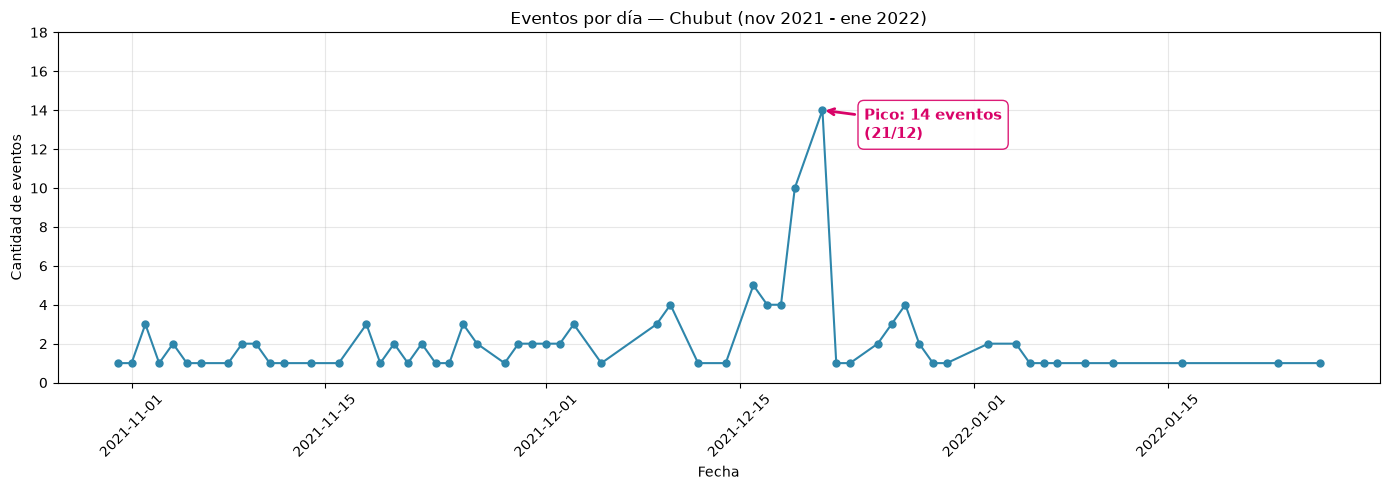

In [11]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(por_dia_ch.index, por_dia_ch.values, marker="o",
        markersize=5, linewidth=1.5, color="#2E86AB")

# Marcar el pico
ax.annotate(f"Pico: {n_pico} eventos\n({dia_pico.strftime('%d/%m')})",
            xy=(dia_pico, n_pico),
            xytext=(30, -20), textcoords="offset points",
            fontsize=11, color="#D90368", fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="#D90368", lw=2),
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                      edgecolor="#D90368", alpha=0.9))

# Dar más aire arriba
ax.set_ylim(0, n_pico + 4)

ax.set_title("Eventos por día — Chubut (nov 2021 - ene 2022)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de eventos")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

La serie diaria muestra una tendencia uniforme de 1 a 5 eventos por día durante la mayor parte del período, con una clara ruptura el 21 de Diciembre de 2021, cuando se registran 14 eventos en un solo dia. concentrando el 12% del total

#### Análisis del pico

In [12]:
dia_pico_str = dia_pico.strftime("%Y%m%d")  # ej: "20211216"

noticias_pico = df_ch[df_ch["fecha"] == dia_pico]

# Mostrar columnas clave
cols_ver = ["noticia_id", "localidad", "tipo_accion", "actores_participantes", "demanda_principal"]
print(f"=== Noticias del {dia_pico.strftime('%d/%m/%Y')} ({len(noticias_pico)} eventos) ===\n")
print(noticias_pico[cols_ver].to_string(index=False))

=== Noticias del 21/12/2021 (14 eventos) ===

noticia_id       localidad     tipo_accion                           actores_participantes                                                         demanda_principal
2021122100 No especificado No especificado                                 No especificado                                                           No especificado
2021122102          Rawson          Marcha                                   manifestantes                               derogación de la ley de zonificación minera
2021122103          Chubut          Marcha                                 No especificado                               Derogación de la Ley de Zonificación Minera
2021122104          Trelew           Corte                          Trabajadores pesqueros       Derogación de la zonificación minera y evitar la nueva Ley de Pesca
2021122104          Esquel           Corte       Vecinos del 'no a la mina'/Ambientalistas                                       

El análisis del pico del 21 de diciembre confirma que la mayoría de los eventos de ese día giraron en torno a la ley de Zonificación Minera. Aparecen tres tipos de acción predominantes —marcha, corte y manifestación— y actores diversos: vecinos autoconvocados, asambleístas, ambientalistas y trabajadores pesqueros. No se trata de un solo actor movilizado, sino de una confluencia multisectorial.

# Análisis de acciones, actores y demandas principales

#### Acciones

In [13]:
print("=== Tipo de accion ===")
print(df_ch['tipo_accion'].value_counts())

=== Tipo de accion ===
tipo_accion
Marcha                    30
Manifestación             23
Corte                     13
Paro                      10
Acto                      10
No especificado            9
Otra                       5
Destrozos                  5
Mixta                      4
Escrache                   4
Toma de edificio           3
Asamblea                   3
Caravana                   1
Difusión de comunicado     1
Name: count, dtype: int64


El repertorio de acciones está dominado por formas convencionales de protesta: marcha (30), manifestación (23) y corte (13). Los paros y actos (10 cada uno) completan el núcleo principal. Las formas disruptivas o violentas son marginales: destrozos (5), escrache (4), toma de edificio (3). Esto sugiere un repertorio mayoritariamente pacífico, con algunos episodios puntuales de ruptura.

Para culminar el análisis de tipos de acción se verán los eventos marcados como "Otra" y "Mixta".

In [14]:
df_ch[df_ch["tipo_accion"] == "Otra"][["noticia_id", "tipo_accion","tipo_accion_detalle","demanda_principal"]]

,noticia_id,tipo_accion,tipo_accion_detalle,demanda_principal
20,2021111800,Otra,No especificado,Pago de salarios atrasados
39,2021113001,Otra,NaN,Llamar a elecciones barriales
43,2021120201,Otra,No aplica,No aplica
64,2021121705,Otra,actos vandálicos,rechazar la zonificación minera
105,2021122800,Otra,NaN,No especificado


In [15]:
df_ch[df_ch["tipo_accion"] == "Mixta"][["noticia_id", "tipo_accion","tipo_accion_detalle","demanda_principal"]]

,noticia_id,tipo_accion,tipo_accion_detalle,demanda_principal
6,2021110400,Mixta,panfleteada y cartelazo,Demandas salariales y edilicias
19,2021111800,Mixta,corte de cuadra con neumáticos y cintas de pel...,Pago de salarios atrasados
28,2021112301,Mixta,Marcha + pintadas en la fachada de la Comisarí...,Muerte de un joven en Cuesta del Ternero
57,2021121600,Mixta,"incendio de Casa de Gobierno, plaza central y ...",Reclamar el veto de la ley de zonificación minera


En general, los tipos de acción mixta se refieren a hechos de carácter vandálico o destrozos, y engloban demandas salariales, una sobre la muerte de una persona y una sobre el reclamo del veto de la ley de zonificación minera.

#### Actores predominantes

In [16]:
COLS_ACTORES = ["docentes", "gremios_estatales", "sindicatos_privados",
                "organizaciones_sociales", "comunidades_indigenas", "vecinos",
                "colectivos_ambientales", "colectivos_especificos",
                "partidos_politicos", "policias_actores",
                "publico_general", "colectivos_violentos", "otros"]


In [17]:
print(" === Actores (n eventos) === ")
print(df_ch[COLS_ACTORES].sum().sort_values(ascending=False))

 === Actores (n eventos) === 
vecinos                    25
gremios_estatales          18
colectivos_ambientales     16
sindicatos_privados        14
publico_general            13
policias_actores            9
colectivos_violentos        6
comunidades_indigenas       6
organizaciones_sociales     5
partidos_politicos          5
docentes                    2
colectivos_especificos      2
otros                       1
dtype: int64


El grupo de actores predominantes son los vecinos (25 eventos), consistente con un conflicto territorial-ambiental organizado desde el territorio. Le siguen gremios estatales (18, principalmente salud —SISAP— y municipales), los colectivos ambientales (16) y los sindicatos privados (14).

La presencia de policías como actores (9 eventos) es un hallazgo particular. La composición refleja un conflicto multisectorial entre diversos actores.

Para profundizar el análisis, veremos un par de casos de actores participantes: policía, vecinos y colectivos ambientales.

In [18]:
df_ch[df_ch["policias_actores"] == 1][["noticia_id", "actores_participantes", "demanda_principal"]]

,noticia_id,actores_participantes,demanda_principal
8,2021110500,Consejo de Bienestar Policial,Reclamo salarial
14,2021111001,Consejo de Bienestar Policial del Chubut,Salario digno para el personal policial
15,2021111100,Consejo de Bienestar Policial/Familia policial,Mejoras salariales para uniformados activos y ...
18,2021111600,Policías/Familias de policías,Mejoras salariales y laborales para policías
19,2021111800,Policía,Pago de salarios atrasados
20,2021111800,Policía,Pago de salarios atrasados
23,2021112000,Policía activo y pasivo,Mejoras salariales y laborales para policías
98,2021122600,Consejo de Bienestar Policial,Renuncia del ministro de Seguridad
99,2021122601,Consejo de Bienestar Policial,Investigar al intendente de Trelew por enviar ...


Se confirma que los eventos donde aparecen los policías como actores de protestas son, en su mayoría, reclamos por salarios atrasados o mejoras laborales, y que en general participan policías, familias de policías o incluso Consejos de Bienestar Policial.

In [19]:
df_ch[df_ch["vecinos"] == 1][["noticia_id", "actores_participantes", "demanda_principal"]]

,noticia_id,actores_participantes,demanda_principal
9,2021110600,amigos/colegas/seguidores de su programa radia...,justicia por el femicidio de la profesora Dani...
12,2021110901,Feriantes del barrio Perón,Exigir pago de 1.000 pesos y costos de espacio...
15,2021111100,Consejo de Bienestar Policial/Familia policial,Mejoras salariales para uniformados activos y ...
18,2021111600,Policías/Familias de policías,Mejoras salariales y laborales para policías
21,2021111801,Familia de Maximiliano Curiqueo,Pide justicia por el crimen de Maximiliano Cur...
24,2021112002,Vecinos de la Meseta del Chubut/Intendentes de...,Aprobación del proyecto de ley de zonificación...
32,2021112502,Vecinos en Emergencia,Presencia de los concejales para explicar la t...
39,2021113001,Vecinos autoconvocados,Llamar a elecciones barriales
41,2021120103,Padres y madres de 6to grado de la Escuela 15,Repudiar el maltrato de la docente y exigir me...
46,2021120302,Dueños de casillas rodantes,Eliminar la obligación de repatentar casillas ...


El desglose de los eventos con vecinos como actores muestra una evolución muy clara:

- Entre el 6 de noviembre y el 12 de diciembre, los reclamos vecinales son heterogéneos: servicios, salarios, femicidios, elecciones locales.
- A partir del 12 de diciembre, y con más intensidad desde el 21, los vecinos se movilizan exclusivamente contra la Ley de Zonificación Minera.

"Vecinos" funciona como categoría miscelánea: agrupa a familiares de víctimas, residentes de barrios afectados y ciudadanos autoconvocados sin pertenencia organizativa previa. Es un indicador de activación territorial amplia, no de un actor cohesionado.

In [20]:
df_ch[df_ch["colectivos_ambientales"] == 1][["noticia_id","actores_participantes","demanda_principal"]]

,noticia_id,actores_participantes,demanda_principal
48,2021120900,antimineros,oposición al proyecto de zonificación minera
49,2021120901,Grupo de manifestantes antimineros,Repudio a la violencia
52,2021121001,Grupos antimineros,Debatir la zonificación minera en la Meseta
54,2021121003,manifestantes antimineros,protestar contra la megaminería
57,2021121600,Asambleístas,Reclamar el veto de la ley de zonificación minera
58,2021121602,Grupos antimineros/Manifestantes,Disconformidad con la política minera
59,2021121604,Asambleístas,Reclamo por la sanción del proyecto de diversi...
60,2021121605,Vecinos de la asamblea del No a la Mina,Rechazo a la Ley de Zonificación minera y soli...
64,2021121705,asambleístas,rechazar la zonificación minera
65,2021121707,Asambleístas,Rechazo a la ley de zonificación minera


Los colectivos ambientales aparecen exclusivamente vinculados al conflicto minero, a partir del 9 de diciembre de 2021, cuando se instala el debate por la ley de Zonificación Minera. Se identifican como "antimineros", "asambleístas" o "ambientalistas", con reclamos centrados en la defensa del agua y el rechazo a la megaminería.

#### Analisis de demandas

In [21]:
COLS_DEMANDAS = ["demanda_salarial", "demanda_laboral", "demanda_ambiental_territorial",
                 "demanda_politica_legal", "demanda_ddhh", "demanda_servicios",
                 "demanda_derechos_especificos", "demanda_institucional",
                 "demanda_conmemoracion"]

print(df_ch[COLS_DEMANDAS].sum().sort_values(ascending=False))

demanda_ambiental_territorial    40
demanda_salarial                 28
demanda_politica_legal           13
demanda_ddhh                     12
demanda_laboral                   8
demanda_institucional             6
demanda_derechos_especificos      5
demanda_servicios                 3
demanda_conmemoracion             0
dtype: int64


El eje principal son las demandas ambientales-territoriales (40 eventos), seguido por las salariales (28) y las político-legales (13). El resto son demandas específicas con menor frecuencia. El conflicto se configura con dos ejes principales —el territorial-ambiental y el laboral— y un eje secundario de tipo político-institucional y de derechos humanos.

In [22]:
df_ch[df_ch["demanda_ambiental_territorial"] == 1][["noticia_id","actores_participantes","demanda_principal"]]

,noticia_id,actores_participantes,demanda_principal
3,2021110202,Miembros de comunidades originarias,solución a la titularidad de tierras
24,2021112002,Vecinos de la Meseta del Chubut/Intendentes de...,Aprobación del proyecto de ley de zonificación...
48,2021120900,antimineros,oposición al proyecto de zonificación minera
52,2021121001,Grupos antimineros,Debatir la zonificación minera en la Meseta
53,2021121002,vecinos y vecinas,restablecer luz y agua
54,2021121003,manifestantes antimineros,protestar contra la megaminería
57,2021121600,Asambleístas,Reclamar el veto de la ley de zonificación minera
58,2021121602,Grupos antimineros/Manifestantes,Disconformidad con la política minera
59,2021121604,Asambleístas,Reclamo por la sanción del proyecto de diversi...
60,2021121605,Vecinos de la asamblea del No a la Mina,Rechazo a la Ley de Zonificación minera y soli...


Desglosando con más detalle las demandas ambientales y territoriales podemos ver que, en su gran mayoría, se relacionan con la ley de zonificación minera, además de otros tipos de demandas.

### Escala / intensidad / disrupción

In [23]:
df_ch["escala"] = df_ch["escala"].astype(str).replace({
    "ALTA": "alta",
    "99.0":"99",
    "Nan":"99",
    "No especificado":"99"
})

df_ch["intensidad"] = df_ch["intensidad"].astype(str).replace({
    "MEDIA": "media",
    "99.0":"99",
    "Nan":"99",
    "No especificado":"99"
})

In [24]:
for col in ["escala", "intensidad", "disrupcion"]:
    print(f"\n=== {col} ===")
    print(df_ch[col].value_counts(dropna=False))


=== escala ===
escala
baja         64
media        32
99           15
alta          9
No aplica     1
Name: count, dtype: int64

=== intensidad ===
intensidad
media        63
baja         33
99           15
alta          9
No aplica     1
Name: count, dtype: int64

=== disrupcion ===
disrupcion
1.0     62
0.0     48
99.0    11
Name: count, dtype: int64


Escala, intensidad, disrupcion
  
- Escala: Predomina la escala baja (64), sobre media (32) y alta (9)
- Intensidad: predomina media (63) sobre baja (33) y alta (9)
- Disrupcion: 62 eventos de caracter disruptivo y 48 no disruptivos 11 no tienen datos suficientes


A continuacion se deglozan los eventos de escala alta e intensidad alta

In [25]:
df_ch[df_ch["escala"] == "alta"][["noticia_id", "tipo_accion", "localidad", "demanda_principal"]]

,noticia_id,tipo_accion,localidad,demanda_principal
5,2021110300,Paro,Chubut,Pago de deuda paritaria y mejoras salariales y...
8,2021110500,Marcha,Rawson,Reclamo salarial
10,2021110800,Manifestación,Rawson,Despedida de 30 trabajadores de la firma GP In...
17,2021111400,Paro,Chubut,Reclamo de pago de paritarias salariales y mej...
24,2021112002,Caravana,Gastre,Aprobación del proyecto de ley de zonificación...
44,2021120300,Corte,Comodoro Rivadavia,Recomposición salarial de los traumatólogos
47,2021120500,Paro,Chubut,Pago de deuda salarial y mejoras laborales
82,2021122103,Marcha,Chubut,Derogación de la Ley de Zonificación Minera
109,2022010200,Destrozos,Trelew,Rechazo a la ley de zonificación minera


Solo 3 eventos de escala alta se refieren al reclamos de la zonificacion minera

In [26]:
df_ch[df_ch["intensidad"] == "alta"][["noticia_id", "tipo_accion", "demanda_principal"]]

,noticia_id,tipo_accion,demanda_principal
5,2021110300,Paro,Pago de deuda paritaria y mejoras salariales y...
10,2021110800,Manifestación,Despedida de 30 trabajadores de la firma GP In...
17,2021111400,Paro,Reclamo de pago de paritarias salariales y mej...
24,2021112002,Caravana,Aprobación del proyecto de ley de zonificación...
44,2021120300,Corte,Recomposición salarial de los traumatólogos
47,2021120500,Paro,Pago de deuda salarial y mejoras laborales
58,2021121602,Manifestación,Disconformidad con la política minera
109,2022010200,Destrozos,Rechazo a la ley de zonificación minera
117,2022011101,Manifestación,Protesta contra la zonificación minera


Solo 4 eventos de intensidad alta corresponden a asuntos de zonificacion minera, el resto son reclamos laborales o salariales

A continuacion tambien veremos los conflictos que comparten escala alta e intensidad alta

In [27]:
df_ch[
    (df_ch["escala"] == "alta") & (df_ch["intensidad"] == "alta")
][["noticia_id", "tipo_accion", "localidad", "demanda_principal"]]

,noticia_id,tipo_accion,localidad,demanda_principal
5,2021110300,Paro,Chubut,Pago de deuda paritaria y mejoras salariales y...
10,2021110800,Manifestación,Rawson,Despedida de 30 trabajadores de la firma GP In...
17,2021111400,Paro,Chubut,Reclamo de pago de paritarias salariales y mej...
24,2021112002,Caravana,Gastre,Aprobación del proyecto de ley de zonificación...
44,2021120300,Corte,Comodoro Rivadavia,Recomposición salarial de los traumatólogos
47,2021120500,Paro,Chubut,Pago de deuda salarial y mejoras laborales
109,2022010200,Destrozos,Trelew,Rechazo a la ley de zonificación minera


En este caso solo hay dos eventos relacionados con la ley de zonificación minera; el resto son reclamos salariales y conflictos laborales.

### Respuesta estatal, uso de fuerza, detenciones, heridos

In [28]:
mask = (df_ch["presencia_policial"] == 99) & (df_ch["uso_fuerza"] == 0)
df_ch.loc[mask, "uso_fuerza"] = 99
mask = (df_ch["presencia_policial"] == 99) & (df_ch["uso_fuerza"] == 1)
df_ch.loc[mask, "uso_fuerza"] = 99

In [29]:
for col in ["presencia_policial", "uso_fuerza",
            "detenciones", "judicializacion"]:
    print(f"\n=== {col} ===")
    print(df_ch[col].value_counts(dropna=False))


=== presencia_policial ===
presencia_policial
99.0    80
1.0     24
0.0     17
Name: count, dtype: int64

=== uso_fuerza ===
uso_fuerza
99.0    81
0.0     36
1.0      4
Name: count, dtype: int64

=== detenciones ===
detenciones
99.0    117
1.0       4
Name: count, dtype: int64

=== judicializacion ===
judicializacion
99.0    75
0.0     39
1.0      7
Name: count, dtype: int64


El análisis de la respuesta estatal está limitado por la baja cobertura de estas variables en la fuente periodística. La presencia policial se registra en solo el 34% de los eventos (24 con presencia, 17 sin presencia, 80 sin datos). El uso de fuerza se confirma en 4 eventos (3,3%), con 36 casos sin uso y 81 sin datos. Las detenciones aparecen en 4 eventos (3,3%). La judicialización es la variable con más información: 7 eventos con causas judiciales (5,8%), 39 sin judicialización (32%) y 75 sin datos (62%).

La alta proporción de valores faltantes no debe interpretarse como ausencia de respuesta estatal. Refleja que la fuente cubre la protesta —actores, demandas, tipo de acción— pero no la represión de forma sistemática.

En términos comparativos, esta limitación es relevante: los datos disponibles no permiten afirmar que la represión haya sido el eje del conflicto de Chubut, pero tampoco lo contrario. La escasa cobertura sobre represión es, sin embargo, consistente con una estrategia estatal de desescalada política (derogación de la ley minera) más que con un disciplinamiento sostenido, aunque esta hipótesis requeriría fuentes complementarias para confirmarse.

Para entender en que manifestaciones se hizo un despliegue policial se relaizara un desgloce

In [30]:
mask = (df_ch["presencia_policial"] == 1)
print(df_ch.loc[mask, ["noticia_id", "demanda_principal"]])

     noticia_id                                  demanda_principal
2    2021110200      falta de convocatoria a paritarias salariales
16   2021111200                   Bloquear descarga de langostinos
19   2021111800                         Pago de salarios atrasados
20   2021111800                         Pago de salarios atrasados
23   2021112000       Mejoras salariales y laborales para policías
26   2021112200                                    No especificado
28   2021112301           Muerte de un joven en Cuesta del Ternero
32   2021112502  Presencia de los concejales para explicar la t...
38   2021113000  Reclamo salarial por pago retroactivo del Conv...
39   2021113001                      Llamar a elecciones barriales
57   2021121600  Reclamar el veto de la ley de zonificación minera
58   2021121602              Disconformidad con la política minera
62   2021121701                                    No especificado
71   2021121901          Ataques incendiarios a edificios públ

Este desglose permite ver que la presencia policial se asocia en menor medida a reclamos salariales y en mayor medida a demandas contra la ley de zonificación minera.


In [31]:
pd.crosstab(df_ch["presencia_policial"], df_ch["uso_fuerza"], dropna=False)

uso_fuerza,0.0,1.0,99.0
presencia_policial,,,
0.0,17,0,0
1.0,19,4,1
99.0,0,0,80


#### Desgloze Judicializacion

In [32]:
df_ch[df_ch["judicializacion"] == 1][["noticia_id", "tipo_accion", "demanda_principal", "actores_participantes"]]

,noticia_id,tipo_accion,demanda_principal,actores_participantes
28,2021112301,Mixta,Muerte de un joven en Cuesta del Ternero,Integrantes de una marcha
33,2021112600,Corte,Reclamo salarial,Hompanera/ATE
90,2021122110,Marcha,Repudio a la ley de zonificación,Asambleístas
101,2021122701,Manifestación,Contra la zonificación minera,No especificado
102,2021122703,Manifestación,Protesta contra la zonificación minera,Imputados
109,2022010200,Destrozos,Rechazo a la ley de zonificación minera,Militantes sociales
113,2022010500,Manifestación,oposición a la ley que habilitaba la explotaci...,grupo reducido de inadaptados/Movimiento de Tr...


La judicialización afecta a 7 eventos (5,8% del total). De esos, 5 corresponden al conflicto minero posterior a la sanción de la Ley de Zonificación (21/12, 27/12, 2/1, 5/1), 1 a un reclamo salarial con corte (26/11) y 1 a la muerte de un joven en Cuesta del Ternero (23/11). Los actores involucrados son asambleístas, militantes sociales, imputados no identificados y un grupo identificado como "inadaptados".

#### Amenaza politica

In [33]:
print(df_ch["amenaza_politica"].value_counts(dropna=False))

amenaza_politica
1.0     63
0.0     34
99.0    16
2.0      6
3.0      2
Name: count, dtype: int64


La amenaza política presenta un patrón de baja intensidad generalizada: 63 eventos con amenaza baja, 34 sin amenaza y solo 8 con amenaza media o alta. Esto sugiere que el conflicto chubutense operó en un contexto de tensión política permanente, pero sin escaladas discursivas extremas. Los 16 casos sin datos probablemente correspondan a eventos donde no se pudo determinar el nivel de amenaza.

Con esto se realizará un desglose para los eventos con amenaza media y alta.

In [34]:
df_ch[df_ch["amenaza_politica"] == 2.0][["noticia_id", "tipo_accion", "demanda_principal", "actores_participantes"]]

,noticia_id,tipo_accion,demanda_principal,actores_participantes
57,2021121600,Mixta,Reclamar el veto de la ley de zonificación minera,Asambleístas
58,2021121602,Manifestación,Disconformidad con la política minera,Grupos antimineros/Manifestantes
68,2021121802,Destrozos,No especificado,turba de exaltados/Revoltosos
88,2021122108,Marcha,Protesta contra la Ley de Zonificación Minera,Vecinos
98,2021122600,Manifestación,Renuncia del ministro de Seguridad,Consejo de Bienestar Policial
117,2022011101,Manifestación,Protesta contra la zonificación minera,No especificado


Los eventos relacionados con amenaza media predomina el conflicto antiminero (4 de 6 eventos)

In [35]:
df_ch[df_ch["amenaza_politica"] == 3.0][["noticia_id", "tipo_accion", "demanda_principal", "actores_participantes"]]

,noticia_id,tipo_accion,demanda_principal,actores_participantes
71,2021121901,Acto,Ataques incendiarios a edificios públicos,Militantes de un sector político
109,2022010200,Destrozos,Rechazo a la ley de zonificación minera,Militantes sociales


Vemos que los eventos con amenaza politica alta son aquellos en los que hubo destrozos o daños a la propiedad

#### Resultado del episodio

In [36]:
print(df_ch["resultado_episodio"].value_counts(dropna=False))

resultado_episodio
0.0     86
99.0    18
1.0     15
2.0      1
3.0      1
Name: count, dtype: int64


En el 71% de los eventos (86 de 121) no se registra un resultado concreto en general son eventos en los cuales el reclamo continua. Solo 17 eventos tuvieron algún tipo de resultado: 15 eventos tuvieron desmovilizacion , 1 tuvo desalojo y 1 tuvo negociaciones. Esto puede interpretarse de dos maneras: o bien la mayoría de las protestas no obtuvieron respuesta estatal, o bien la fuente periodística no cubrió los desenlaces. Dado que el período termina con la derogación de la Ley de Zonificación Minera tras el pico del 21 de diciembre, es probable que la segunda interpretación sea parcialmente correcta: el resultado más importante del período (la derogación) no aparece codificado como "resultado" de ningún evento puntual.

### Nota sobre escalas

Las variables `amenaza_politica` y `resultado_episodio` usan escalas ordinales:

- `amenaza_politica`: 0 = sin amenaza, 1 = baja, 2 = media, 3 = alta, 99 = sin datos.
- `resultado_episodio`: 0 = continua, 1 = desmovilizacion, 2 = desalojo, 3 = negociacion, 99 = sin datos.

Estas escalas se definieron en la fase de codificación y se describen en el codebook del proyecto.

### Crosstabs

In [37]:
top_localidades = df_ch["localidad"].value_counts().head(6).index.tolist()

ct = pd.crosstab(
    df_ch[df_ch["localidad"].isin(top_localidades)]["localidad"],
    df_ch[df_ch["localidad"].isin(top_localidades)]["tipo_accion"]
)
ct

tipo_accion,Acto,Asamblea,Corte,Destrozos,Difusión de comunicado,Escrache,Manifestación,Marcha,Mixta,No especificado,Otra,Paro,Toma de edificio
localidad,,,,,,,,,,,,,
Chubut,0,0,2,0,1,0,5,4,0,0,0,4,0
Esquel,2,2,1,0,0,4,2,2,0,0,0,1,2
No especificado,1,0,0,0,0,0,1,1,0,7,0,0,0
Puerto Madryn,1,0,1,0,0,0,0,3,1,0,1,1,0
Rawson,3,0,2,4,0,0,4,6,1,1,2,3,0
Trelew,2,1,1,1,0,0,6,10,2,1,1,0,0


Los cruces entre localidad y tipo de acción muestran que Trelew y Rawson concentran la mayor diversidad de repertorios. Trelew tiene el mayor número de marchas (10) y manifestaciones (6); Rawson combina marchas (6), manifestaciones (4), actos (3) y destrozos (4). Esquel muestra un patrón más heterogéneo, con presencia de escraches (4) y tomas de edificio (2). Puerto Madryn y Comodoro Rivadavia aparecen con menor volumen, con predominio de marchas.

In [38]:
tabla_accion_disrupcion = pd.crosstab(df_ch['tipo_accion'], df_ch['disrupcion'])
tabla_accion_disrupcion = tabla_accion_disrupcion.round(2)

print("tipo de accion vs disrupccion")
tabla_accion_disrupcion

tipo de accion vs disrupccion


disrupcion,0.0,1.0,99.0
tipo_accion,,,
Acto,3,7,0
Asamblea,2,1,0
Caravana,0,1,0
Corte,0,13,0
Destrozos,0,5,0
Difusión de comunicado,1,0,0
Escrache,0,4,0
Manifestación,13,10,0
Marcha,26,4,0


El cruce entre tipo de acción y disrupción confirma la coherencia de la codificación. Las acciones que por definición implican disrupción —corte, caravana, destrozos, escrache, paro y toma— presentan disrupción en todos sus casos. Las acciones que pueden o no ser disruptivas —manifestación, marcha, acto— se distribuyen según el contexto. La marcha es mayormente no disruptiva (26 de 30), mientras que la manifestación se reparte casi por mitades (13 sin disrupción, 10 con disrupción).

# Conclusiones

El análisis exploratorio de los 121 eventos de protesta registrados en Chubut entre octubre de 2021 y enero de 2022 permite reconstruir un ciclo de conflicto con dos fases nítidas y un evento estructurante que reorganiza todo el período: el debate y la sanción de la Ley de Zonificación Minera.

El recorte temporal no es arbitrario: empieza con protestas dispersas de carácter sectorial y termina con la derogación de la ley minera, tras un pico de movilización multisectorial sin precedentes en el período. Ese arco es el que da sentido a los datos.

### Hallazgos

El período tiene dos momentos bien distintos. Entre octubre y noviembre las protestas son salariales y laborales, con gremios y policías como protagonistas y repertorios convencionales. A partir de diciembre el conflicto se territorializa: vecinos, asambleas, demandas ambientales y un repertorio más disruptivo. Los reclamos salariales siguen, pero quedan desplazados.

Sin la Ley de Zonificación Minera, el período sería una sucesión de reclamos sectoriales sin conexión entre sí. La ley funcionó como punto de encuentro para actores que hasta entonces protestaban por separado: vecinos, asambleístas, ambientalistas, trabajadores pesqueros, gremios y partidos. Eso explica el pico del 21 de diciembre (14 eventos, 12% del total) y por qué el conflicto siguió hasta enero, incluso después de la derogación

De 121 eventos, solo 12 son violentos o de alta disruptividad. El resto son marchas, manifestaciones, cortes y paros. Los episodios de violencia están acotados a días puntuales (16/12, 18/12, 2/1) y no se generalizan. Comparado con otros conflictos socioambientales del período, Chubut se destaca por un repertorio bastante pacífico.

Las variables de respuesta estatal tienen entre 60% y 97% de valores faltantes. Con lo que hay, la presencia policial documentada es limitada (24 eventos), el uso de fuerza aparece en 4 y hay 4 detenciones registradas. La estrategia estatal parece haber sido de desescalada política más que de represión sostenida: la ley se derogó días después del pico.

No obstante la ausencia de datos no es evidencia de ausencia de represión. La fuente cubre bien la protesta y mal la respuesta estatal. Para afirmar algo más fuerte harían falta fuentes complementarias.

La categoría "vecinos" es la más numerosa (25 eventos) pero no designa un actor cohesionado: adentro entran familiares de víctimas, residentes afectados y autoconvocados sin pertenencia previa. Lo interesante es cuándo aparece: antes del 12 de diciembre los reclamos son heterogéneos; desde el 21 aparecen exclusivamente en el conflicto minero. La categoría funciona como indicador de activación territorial, no como actor.

Hay 9 eventos donde los policías aparecen como actores de protesta, no como agentes de control. Casi todos son reclamos salariales, con participación de familias y Consejos de Bienestar Policial. Vale la pena no confundir "policías_actores" (policías protestando) con "presencia_policial" (policías controlando la protesta).